Name Isabelle Maru Shapiro

Labpartner(s)

In [1]:
#import statements go here
import pandas as pd
import matplotlib.pyplot as plt 


# Class 8.2

Today we are having a guest lecture online by [Will Faulkner](https://www.linkedin.com/in/wnfaulkner/) on "vibe coding" aka the use of LLMs to build code when you have no or little idea what you are doing. 

**W.1** This week our warmups are focused on applying your Pandas skills. Please continue your analysis of the 2026 World Cup player stats from slack (pinned to #announcements). Make sure you write some text about what you found. 

In [2]:
data = pd.read_csv("player_stats.csv")
data.head(20)

,player_id,player_name,team_id,position,matches_played,matches_started,minutes_played,goals,assists,shots,...,yellow_cards,red_cards,penalty_goals,own_goals,clean_sheets,saves,goals_conceded,average_rating,data_source,last_verified
0,1,José Raúl Rangel,1,GK,5,5,438,0,0,NaN,...,0,0,0,0,4.0,7.0,3.0,NaN,sofascore.com,2026-07-19
1,2,Jorge Eduardo Sanchez,1,DEF,5,5,439,0,1,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
2,3,César Jasib Montes,1,DEF,3,2,165,0,0,NaN,...,0,1,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
3,4,Edson Omar Alvarez,1,DEF,2,0,75,0,0,NaN,...,1,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
4,5,Johan Felipe Vasquez,1,DEF,2,2,180,0,0,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
5,6,Erik Antonio Lira,1,MID,5,5,450,0,1,NaN,...,1,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
6,7,Luis Francisco Romo,1,MID,4,2,194,1,1,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
7,8,Álvaro Fidalgo,1,MID,2,0,41,1,0,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
8,9,Raúl Alonso Jimenez,1,FWD,3,2,193,3,0,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
9,10,Ernesto Alexis Vega,1,FWD,0,0,0,0,0,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2026-07-19


(array([356.,  89., 108.,  78., 102.,  66.,  81., 129.,  36.,  88.,  36.,
         16.,  26.,   2.,  13.,   9.,   6.,   4.,   1.,   2.]),
 array([  0. ,  37.5,  75. , 112.5, 150. , 187.5, 225. , 262.5, 300. ,
        337.5, 375. , 412.5, 450. , 487.5, 525. , 562.5, 600. , 637.5,
        675. , 712.5, 750. ]),
 <BarContainer object of 20 artists>)

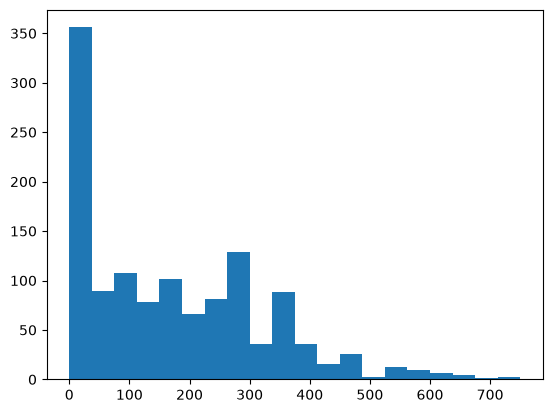

In [3]:
plt.hist(data.minutes_played, bins = 20)

In [4]:
GK = data[data['position'] == "GK"]
DEF = data[data['position'] == "DEF"]
FWD = data[data['position'] == "FWD"]
MID = data[data['position'] == "MID"]

<Axes: >

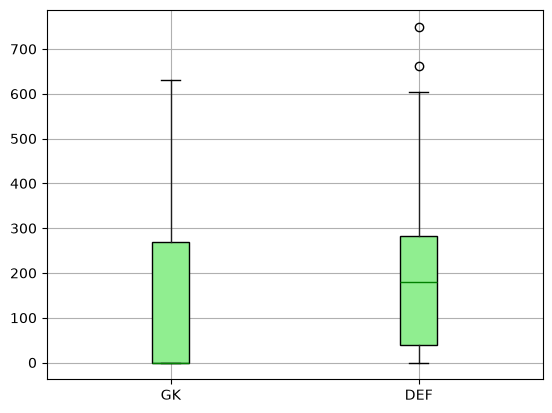

In [8]:
fig, ax = plt.subplots()
#ax.boxplot(GK.minutes_played)
#ax.boxplot(DEF.minutes_played)

combined = pd.concat([GK['minutes_played'], DEF['minutes_played']],axis = 1)
#combined = pd.concat([FWD['minutes_played'], MID['minutes_played']], axis = 1)
#combined.columns = ['FWD', 'MID']
combined.columns = ['GK', 'DEF']
combined.boxplot(showfliers = True, patch_artist = True, boxprops = dict(facecolor = "lightgreen"), medianprops = dict(color = "green"))


# Lecture 8.2

### Agenda: Will will talk about vibe coding, we'll have a break, and then he'll share some examples


### Questions

# Lab 8.2

**E.0** Complete the previous labs if you are behind.

**E.1** "Vibe coding" in practice, part 1. Take a dataset of your choice and use an LLM to do some kind of manipulation or analysis of that data. You should focus on trying something that you couldn't easily figure out on your own. Paste the resulting code and results here.

In [ ]:
#Using GLODAP Pacific ocean bottle data 
import pandas as pd

df = pd.read_csv("GLODAPv3_Pacific_Ocean.csv", na_values = -9999)

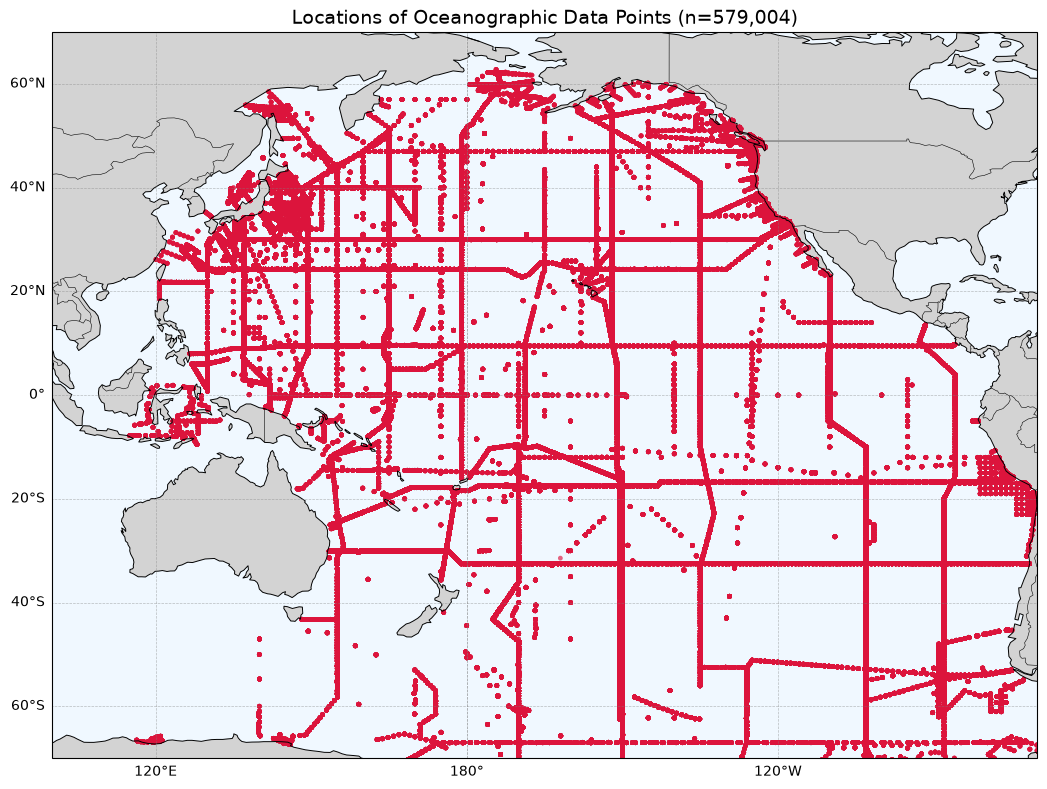

In [37]:
#Plot all data 
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 2. Remove rows with missing or invalid coordinates
df = df.dropna(subset=["longitude", "latitude"])
df = df[
    df["longitude"].between(-180, 180) &
    df["latitude"].between(-90, 90)
]

# 3. Create a map centered on the Pacific Ocean
fig = plt.figure(figsize=(14, 8))

ax = plt.axes(
    projection=ccrs.PlateCarree(central_longitude=180)
)

# Set map extent: Pacific Ocean
ax.set_extent([100, 290, -70, 70],
              crs=ccrs.PlateCarree())

# 4. Add geographic features
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

# 5. Plot all data locations
ax.scatter(
    df["longitude"],
    df["latitude"],
    transform=ccrs.PlateCarree(),
    s=12,                 # Point size
    color="crimson",
    alpha=0.65,
    edgecolors="none"
)

# 6. Add gridlines and labels
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.5,
    color="gray",
    alpha=0.5,
    linestyle="--"
)
gl.top_labels = False
gl.right_labels = False

ax.set_title(
    f"Locations of Oceanographic Data Points (n={len(df):,})",
    fontsize=14
)

plt.tight_layout()
plt.savefig("pacific_data_locations.png", dpi=300,
            bbox_inches="tight")
plt.show()

In [39]:
#determine if a given cruise is vertical or horizontal 
import pandas as pd
import numpy as np

def classify_cruise(df, cruise_id):

    # Convert cruise IDs and coordinates to numeric
    df = df.copy()
    df["cruise"] = pd.to_numeric(df["cruise"], errors="coerce")
    df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
    df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

    # Select the requested cruise
    cruise = df[df["cruise"] == float(cruise_id)].copy()

    print(f"Rows matching cruise {cruise_id}: {len(cruise)}")

    # Remove missing coordinates
    cruise = cruise.dropna(subset=["latitude", "longitude"])

    if cruise.empty:
        print(f"No coordinate data found for cruise {cruise_id}.")
        return None

    # Calculate geographic extent
    lat_range = cruise["latitude"].max() - cruise["latitude"].min()

    # Unwrap longitude to handle crossing the international dateline
    lon_rad = np.unwrap(np.deg2rad(cruise["longitude"].to_numpy()))
    lon_range = np.rad2deg(lon_rad.max() - lon_rad.min())

    mean_lat = cruise["latitude"].mean()

    # Approximate distances in km
    north_south_km = lat_range * 111.32
    east_west_km = lon_range * 111.32 * np.cos(np.deg2rad(mean_lat))

    # Classify orientation
    if np.isclose(north_south_km, east_west_km, rtol=0.05):
        orientation = "Diagonal or mixed"
    elif north_south_km > east_west_km:
        orientation = "Vertical (north-south)"
    else:
        orientation = "Horizontal (east-west)"

    print(f"Latitude range: {lat_range:.2f} degrees")
    print(f"Longitude range: {lon_range:.2f} degrees")
    print(f"North-south extent: {north_south_km:.1f} km")
    print(f"East-west extent: {east_west_km:.1f} km")
    print(f"Orientation: {orientation}")

    return orientation


# Test cruise 94
classify_cruise(df, 363)

Rows matching cruise 363: 6344
Latitude range: 67.55 degrees
Longitude range: 17.84 degrees
North-south extent: 7519.4 km
East-west extent: 1846.8 km
Orientation: Vertical (north-south)


'Vertical (north-south)'

**E.2** "Vibe coding" in practice, part 2. Now take the same data set and make some kind of plot, again focusing on something that would be difficult to figure out on your own. Paste the resulting code and results here.

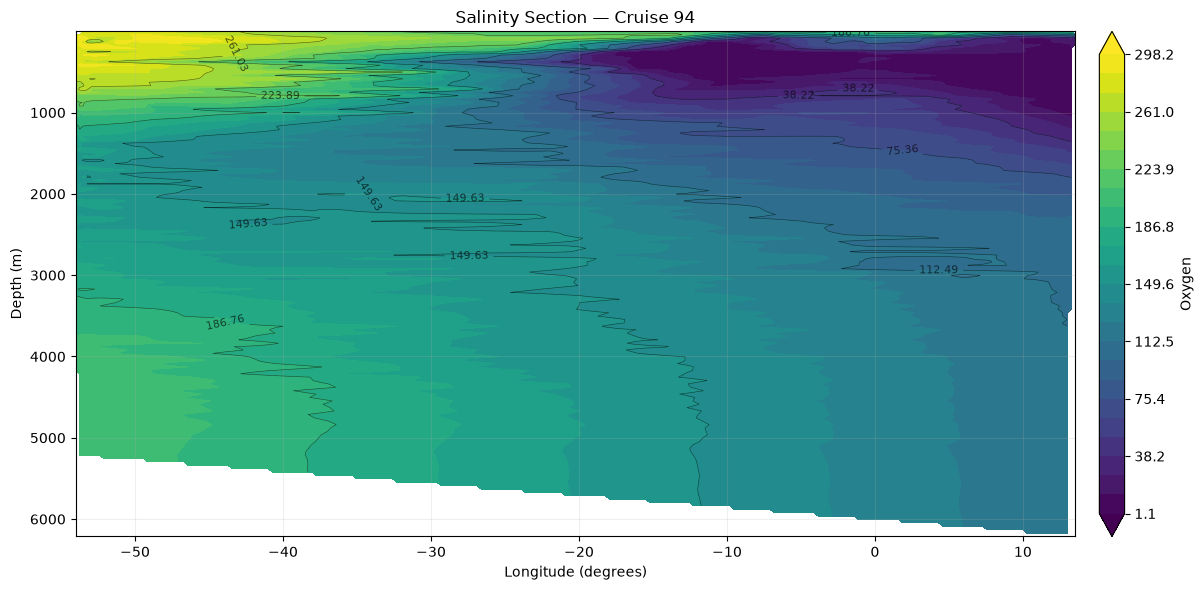

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata


# 2. Select cruise 94
# Convert to string so this works whether cruise is stored
# as a number (94) or text ("94")
cruise = df[df["cruise"] == 363].copy()

# Remove rows with missing values
cruise = cruise.dropna(
    subset=["oxygen", "depth", "latitude", "longitude"]
)

if cruise.empty:
    raise ValueError("No valid data found for cruise 363.")

# 3. Sort by longitude for a longitude-depth section
#cruise = cruise.sort_values("longitude")

# 3. Sort by latitude for a latidue-depth section
cruise = cruise.sort_values("latitude")

# Average duplicate longitude/depth measurements
section = (
    cruise.groupby(["latitude", "depth"], as_index=False)
    ["oxygen"].mean()
)

# 4. Create a regular longitude-depth grid
lon_grid = np.linspace(
    section["latitude"].min(),
    section["latitude"].max(),
    250
)
depth_grid = np.linspace(
    section["depth"].min(),
    section["depth"].max(),
    150
)

LON, DEPTH = np.meshgrid(lon_grid, depth_grid)

# 5. Interpolate salinity
points = section[["latitude", "depth"]].to_numpy()
values = section["oxygen"].to_numpy()

SAL = griddata(
    points,
    values,
    (LON, DEPTH),
    method="linear"
)

# 6. Plot the salinity section
fig, ax = plt.subplots(figsize=(13, 6))

levels = np.linspace(
    np.nanmin(SAL),
    np.nanmax(SAL),
    25
)

contour = ax.contourf(
    LON,
    DEPTH,
    SAL,
    levels=levels,
    cmap="viridis",
    extend="both"
)

# Add salinity contour lines
lines = ax.contour(
    LON,
    DEPTH,
    SAL,
    levels=levels[::3],
    colors="black",
    linewidths=0.4,
    alpha=0.6
)
ax.clabel(lines, inline=True, fontsize=8, fmt="%.2f")

# Colorbar
cbar = fig.colorbar(contour, ax=ax, pad=0.02)
cbar.set_label("Oxygen")

# Labels and formatting
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Depth (m)")
ax.set_title("Salinity Section — Cruise 94")
ax.invert_yaxis()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("cruise_94_salinity_section.png", dpi=300)
plt.show()

**E.3** Now let's think, does your use of AI in the examples above fit into Wiley's best practices framework? What are the dangers and oppertunities here? Use specific examples from the Wiley resources and relate them to your workflow above:

https://www.wiley.com/en-us/publishing/book/ai-guidelines

https://www.wiley.com/en-us/publishing/article/ai-guidelines

Specifically, when is it ethical to use AI for research, and when is it not? When is it in your best interest as a student to use AI, and when is it not? What are the enviornmental considerations of using AI? How might you use AI in your final project in line with ethical guidelines? You should be writng a few paragraphs at minimum with examples here. 


The Wiley guidelines say that is it ethical to use AI for research when it is a "companion" not replacement.  They highlight using it as an editing tool and to create content that isn't directly reflecting data or results in published work.  They also mention the importance of checking copyright and privacy rules before putting any unpublished or sensitive data into an ai tool.  

According to the guidelines, I could probably get away with what I did with my data in this lab, although I would have to double check aspects of it to verify it is doing exactly what I want it to.  If I had AI create an entirely new figure based on data that I fed into it, that would not be acceptable, but because AI gave me a code that I ran myself to create a figure, that is more acceptable because the figure is reproducable.  Because the AI never actually saw my data, I just decribed it, I know that no unexpected data manipulation happened beyond what is written in the code.  

As a student, I think there are few opprotunities for AI use to be in my best interest.  Often times AI removed the critical thinking portion of an assignment, and it is very easy to cut corners using it.  I could see an senario where a student is on a tight deadline for a project and uses AI for a part of the work that the teacher specifically says they aren't going to be graded on in order to finish more quickly, but ideally a student is never really in that position.  AI also can be pretty expensive--A "max" subscription to claude costs $100 monthly, where you can get better/faster usage out of the AI.  Especially for a student, that is a lot of money.  One thing that really worries me about AI is that people will get so used to relying on it for things that they previously could have done themselves, and then eventally the AI companies will raise their prices enough that people no longer can afford it. It seems like a bad idea to rely on something that has such an unclear future as a student, especially when I am already in school to learn it anyway.

Beyond the personal impacts of using AI there is the environmental impact. The data centers use a lot of energy and water to run, which can have huge environmental and health impacts in the areas that they are built. Lots of the specific environmenal impacts of ai are not very well constrained because a lack of information and because ai technology has changed so much in the last couple years. 

I personally don't think if I can ethically encorporate ai into my final project because because of the combination of the environmental impacts of ai and the fear that I won't learn as much by using it. I think there are places that AI can be ethically used a very helpful, for example if it is used to screen for cancer and can reconize symptoms sooner than a human doctor can. I don't think I am ever going to be working on data that is urgent or life-threatening enough that using ai would be justified when I could just do it myself and have a smaller environmental impact and feel less guilty, and hopefully learn more. 

https://www.cnn.com/2026/10/16/climate/ai-environmental-impact-energy-water-noise-explainer

**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.